In [13]:
import math
import matplotlib.pyplot as plt

INF = math.inf

def fmt(v):
    if v == INF:
        return "+inf"
    if v == -INF:
        return "-inf"
    return str(v)

class Node:
    def __init__(self, kind, value=None):
        self.kind = kind
        self.value = value
        self.children = []
        self.visited = False
        self.alpha = None
        self.beta = None
        self.cut = False
        self.x = self.y = 0

def build_tree(data, maximizing=True):
    if not isinstance(data, list):
        return Node("LEAF", data)
    node = Node("MAX" if maximizing else "MIN")
    node.children = [build_tree(child, not maximizing) for child in data]
    return node

def alphabeta(node, alpha, beta, depth=0, stats=None):
    node.visited = True
    indent = "    " * depth
    if node.kind == "LEAF":
        stats["leaves"] += 1
        print(f"{indent}leaf = {node.value}")
        return node.value
    maximizing = node.kind == "MAX"
    value = -INF if maximizing else INF
    print(f"{indent}{node.kind} node alpha={fmt(alpha)} beta={fmt(beta)}")
    for i, child in enumerate(node.children):
        child_val = alphabeta(child, alpha, beta, depth + 1, stats)
        if maximizing:
            value = max(value, child_val)
            alpha = max(alpha, value)
        else:
            value = min(value, child_val)
            beta = min(beta, value)
        if alpha >= beta:
            remaining = len(node.children) - i - 1
            if remaining > 0:
                node.cut = True
                stats["cuts"] += 1
                print(f"{indent}  >>> PRUNE remaining {remaining} child(ren): alpha={fmt(alpha)} >= beta={fmt(beta)}")
            break
    node.value = value
    node.alpha = alpha
    node.beta = beta
    print(f"{indent}{node.kind} returns {fmt(value)}")
    return value

def layout(node, depth=0, counter=None):
    node.y = -depth * 1.6
    if node.kind == "LEAF":
        node.x = counter[0]
        counter[0] += 1
    else:
        for child in node.children:
            layout(child, depth + 1, counter)
        node.x = sum(child.x for child in node.children) / len(node.children)

def draw_tree(root, title, filename):
    layout(root, 0, [0])
    fig, ax = plt.subplots(figsize=(18, 8))
    def walk(node):
        for i, child in enumerate(node.children):
            pruned = not child.visited
            ax.plot([node.x, child.x], [node.y, child.y], color="#aaa" if pruned else "black", linestyle="--" if pruned else "-", linewidth=1.8, zorder=1)
            if pruned and (i == 0 or node.children[i - 1].visited):
                mx = (node.x + child.x) / 2
                my = (node.y + child.y) / 2
                ax.plot([mx - 0.12, mx + 0.12], [my - 0.12, my + 0.12], color="red", linewidth=3, zorder=4)
                ax.plot([mx - 0.12, mx + 0.12], [my + 0.12, my - 0.12], color="red", linewidth=3, zorder=4)
            walk(child)
        marker = {"MAX": "^", "MIN": "v", "LEAF": "s"}[node.kind]
        color = "#d5d8dc" if not node.visited else {"MAX": "#58d68d", "MIN": "#f1948a", "LEAF": "#f9e79f"}[node.kind]
        ax.scatter(node.x, node.y, s=1500, marker=marker, color=color, edgecolor="black", linewidth=2, zorder=3)
        if node.visited:
            ax.text(node.x, node.y, fmt(node.value), ha="center", va="center", fontsize=13, fontweight="bold", zorder=5)
            if node.kind != "LEAF":
                ax.text(node.x, node.y + 0.5, f"a={fmt(node.alpha)} b={fmt(node.beta)}", ha="center", fontsize=9, color="#1a5276")
                if node.cut:
                    ax.text(node.x, node.y - 0.55, "a >= b : PRUNE", ha="center", fontsize=9, color="red", fontweight="bold")
        else:
            ax.text(node.x, node.y, "x", ha="center", va="center", fontsize=12, color="#777", zorder=5)
    walk(root)
    handles = [
        plt.Line2D([0], [0], marker="^", color="w", markerfacecolor="#58d68d", markeredgecolor="black", markersize=14, label="MAX node"),
        plt.Line2D([0], [0], marker="v", color="w", markerfacecolor="#f1948a", markeredgecolor="black", markersize=14, label="MIN node"),
        plt.Line2D([0], [0], marker="s", color="w", markerfacecolor="#f9e79f", markeredgecolor="black", markersize=12, label="Leaf (utility)"),
        plt.Line2D([0], [0], marker="s", color="w", markerfacecolor="#d5d8dc", markeredgecolor="black", markersize=12, label="Pruned (never evaluated)"),
        plt.Line2D([0], [0], color="red", linewidth=3, label="Cut-off")
    ]
    ax.legend(handles=handles, loc="upper left", fontsize=11)
    ax.set_ylim(-7.3, 1.3)
    ax.set_title(title, fontsize=16, fontweight="bold", pad=14)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(filename, dpi=130)
    plt.show()
    print("Image saved:", filename)

nodes = 0

def minimax_nim(stones, maximizing):
    global nodes
    nodes += 1
    if stones == 0:
        return -1 if maximizing else 1
    values = [minimax_nim(stones - take, not maximizing) for take in (1, 2, 3) if take <= stones]
    return max(values) if maximizing else min(values)

def alphabeta_nim(stones, alpha, beta, maximizing):
    global nodes
    nodes += 1
    if stones == 0:
        return -1 if maximizing else 1
    if maximizing:
        value = -INF
        for take in (1, 2, 3):
            if take <= stones:
                value = max(value, alphabeta_nim(stones - take, alpha, beta, False))
                alpha = max(alpha, value)
                if alpha >= beta:
                    break
        return value
    value = INF
    for take in (1, 2, 3):
        if take <= stones:
            value = min(value, alphabeta_nim(stones - take, alpha, beta, True))
            beta = min(beta, value)
            if alpha >= beta:
                break
    return value

def best_nim_move(stones):
    best, best_val = 1, -INF
    for take in (1, 2, 3):
        if take <= stones:
            value = alphabeta_nim(stones - take, -INF, INF, False)
            if value > best_val:
                best, best_val = take, value
    return best

def compare_nim(max_n=20):
    global nodes
    sizes = list(range(4, max_n + 1))
    mm, ab = [], []
    print(f"\n{'Stones':>7} {'Minimax nodes':>15} {'Alpha-Beta nodes':>18} {'Saved':>8}")
    for n in sizes:
        nodes = 0
        result1 = minimax_nim(n, True)
        mm.append(nodes)
        nodes = 0
        result2 = alphabeta_nim(n, -INF, INF, True)
        ab.append(nodes)
        assert result1 == result2
        saved = 100 * (1 - ab[-1] / mm[-1])
        print(f"{n:>7} {mm[-1]:>15} {ab[-1]:>18} {saved:>7.1f}%")
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    ax[0].plot(sizes, mm, "o-", color="#c0392b", linewidth=2.5, label="Minimax")
    ax[0].plot(sizes, ab, "s-", color="#27ae60", linewidth=2.5, label="Alpha-Beta")
    ax[0].set_yscale("log")
    ax[0].set_xlabel("Number of stones")
    ax[0].set_ylabel("Nodes searched (log scale)")
    ax[0].set_title("Search effort: Minimax vs Alpha-Beta", fontweight="bold")
    ax[0].grid(alpha=0.3)
    ax[0].legend(fontsize=12)
    saved = [100 * (1 - a / m) for a, m in zip(ab, mm)]
    ax[1].bar(sizes, saved, color="#2e86c1")
    ax[1].set_xlabel("Number of stones")
    ax[1].set_ylabel("% of nodes saved by pruning")
    ax[1].set_title("Work saved by Alpha-Beta pruning", fontweight="bold")
    ax[1].grid(axis="y", alpha=0.3)
    fig.suptitle("Lab 11 - Alpha-Beta Pruning applied to the game of Nim", fontsize=16, fontweight="bold")
    fig.tight_layout()
    fig.savefig("lab11_nim_output.png", dpi=150)
    plt.show()
    print("Image saved: lab11_nim_output.png")

def demo_game(stones=15):
    global nodes
    print(f"\nDEMO GAME - {stones} stones, human always takes 1")
    human_turn = True
    while stones > 0:
        if human_turn:
            take = 1
            print(f"  Human takes {take} -> {stones - take} left")
        else:
            nodes = 0
            take = best_nim_move(stones)
            print(f"  Computer takes {take} -> {stones - take} left (searched {nodes} nodes)")
        stones -= take
        if stones == 0:
            print("  Winner:", "Human" if human_turn else "Computer")
        human_turn = not human_turn

def play_game(stones=15):
    global nodes
    print(f"\nNIM - {stones} stones. Take 1-3. Taking the last stone wins.")
    human_turn = True
    while stones > 0:
        print(f"\nStones left: {stones} " + "o " * stones)
        if human_turn:
            while True:
                try:
                    take = int(input("Your move (1-3): "))
                    if 1 <= take <= 3 and take <= stones:
                        break
                except ValueError:
                    pass
                print("Invalid move.")
        else:
            nodes = 0
            take = best_nim_move(stones)
            print(f"Computer takes {take} (searched {nodes} nodes)")
        stones -= take
        if stones == 0:
            print("\nYou win!" if human_turn else "\nComputer wins!")
        human_turn = not human_turn

LAB 11: ALPHA-BETA PRUNING

PART A - Alpha-Beta on a game tree (root = MAX)

MAX node alpha=-inf beta=+inf
    MIN node alpha=-inf beta=+inf
        MAX node alpha=-inf beta=+inf
            MIN node alpha=-inf beta=+inf
                leaf = 3
                leaf = 5
            MIN returns 3
            MIN node alpha=3 beta=+inf
                leaf = 6
                leaf = 9
            MIN returns 6
        MAX returns 6
        MAX node alpha=-inf beta=6
            MIN node alpha=-inf beta=6
                leaf = 1
                leaf = 2
            MIN returns 1
            MIN node alpha=1 beta=6
                leaf = 0
              >>> PRUNE remaining 1 child(ren): alpha=1 >= beta=0
            MIN returns 0
        MAX returns 1
    MIN returns 1
    MIN node alpha=1 beta=+inf
        MAX node alpha=1 beta=+inf
            MIN node alpha=1 beta=+inf
                leaf = 4
                leaf = 7
            MIN returns 4
            MIN node alpha=4 beta=+inf
   

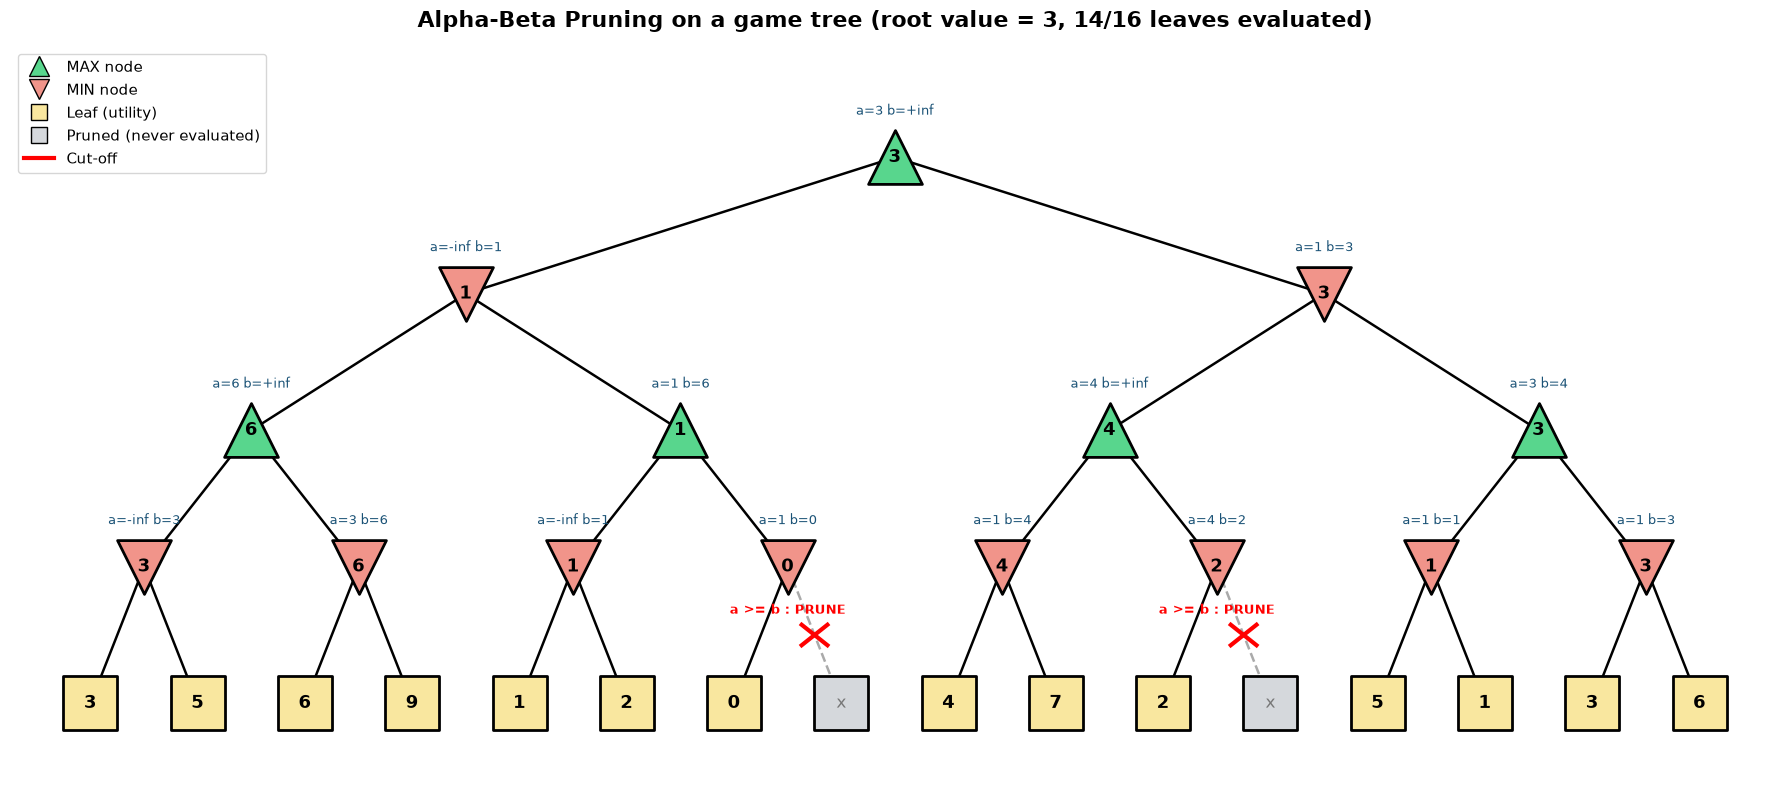

Image saved: lab11_tree_output.png



In [14]:
print("=" * 66)
print("LAB 11: ALPHA-BETA PRUNING")
print("=" * 66)
print("\nPART A - Alpha-Beta on a game tree (root = MAX)\n")
leaves = [3, 5, 6, 9, 1, 2, 0, -1, 4, 7, 2, 8, 5, 1, 3, 6]
data = [
    [
        [[leaves[0], leaves[1]], [leaves[2], leaves[3]]],
        [[leaves[4], leaves[5]], [leaves[6], leaves[7]]]
    ],
    [
        [[leaves[8], leaves[9]], [leaves[10], leaves[11]]],
        [[leaves[12], leaves[13]], [leaves[14], leaves[15]]]
    ]
]
root = build_tree(data, True)
stats = {"leaves": 0, "cuts": 0}
result = alphabeta(root, -INF, INF, 0, stats)
print(f"\nOptimal value at root: {result}")
print(f"Leaves evaluated: {stats['leaves']} of {len(leaves)}")
print(f"Cut-offs (pruning events): {stats['cuts']}")
draw_tree(root, f"Alpha-Beta Pruning on a game tree (root value = {result}, {stats['leaves']}/{len(leaves)} leaves evaluated)", "lab11_tree_output.png")
print("\n" + "=" * 66)

PART B - Application: game of NIM

 Stones   Minimax nodes   Alpha-Beta nodes    Saved
      4              15                 15     0.0%
      5              28                 24    14.3%
      6              52                 45    13.5%
      7              96                 77    19.8%
      8             177                134    24.3%
      9             326                180    44.8%
     10             600                329    45.2%
     11            1104                578    47.6%
     12            2031                987    51.4%
     13            3736               1203    67.8%
     14            6872               2205    67.9%
     15           12640               3993    68.4%
     16           23249               6797    70.8%
     17           42762               7797    81.8%
     18           78652              14470    81.6%
     19          144664              26870    81.4%
     20          266079              45872    82.8%


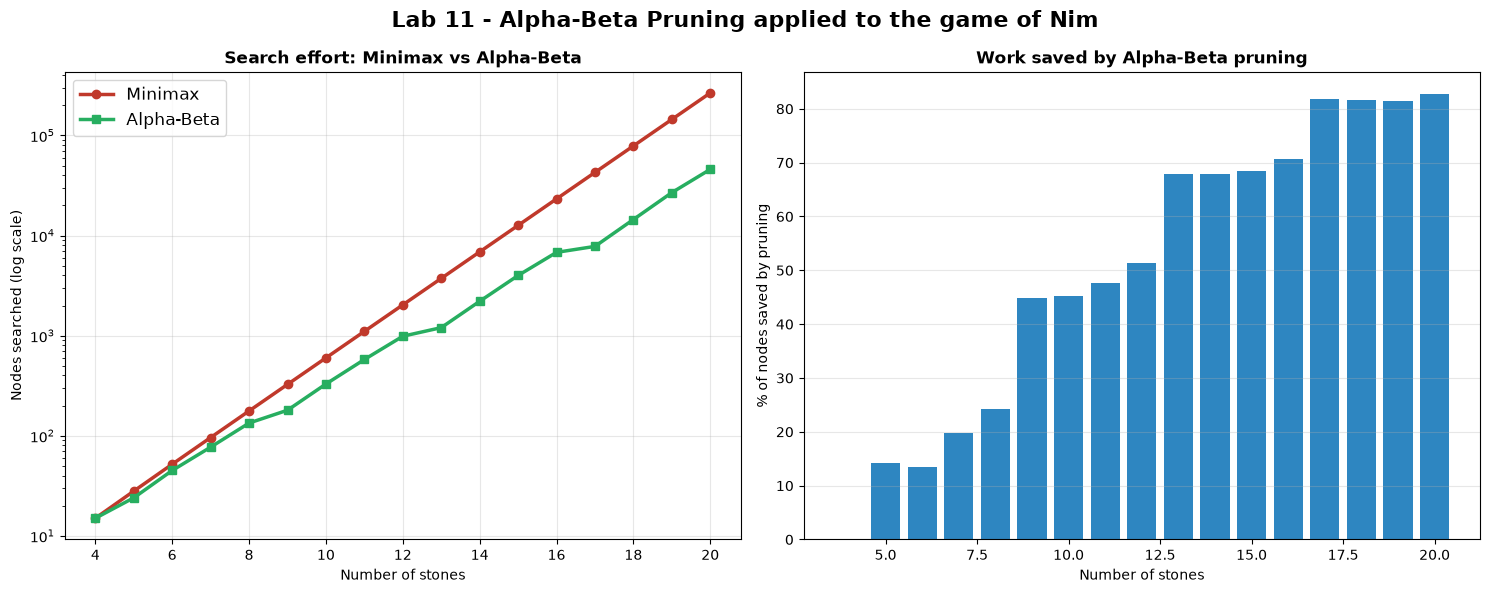

Image saved: lab11_nim_output.png

DEMO GAME - 15 stones, human always takes 1
  Human takes 1 -> 14 left
  Computer takes 2 -> 12 left (searched 2768 nodes)
  Human takes 1 -> 11 left
  Computer takes 3 -> 8 left (searched 643 nodes)
  Human takes 1 -> 7 left
  Computer takes 3 -> 4 left (searched 84 nodes)
  Human takes 1 -> 3 left
  Computer takes 3 -> 0 left (searched 7 nodes)
  Winner: Computer

Lab 11 completed successfully.


In [15]:
print("PART B - Application: game of NIM")
print("=" * 66)
compare_nim(20)
demo_game(15)
print("\nLab 11 completed successfully.")

In [16]:
play_game(15)


NIM - 15 stones. Take 1-3. Taking the last stone wins.

Stones left: 15 o o o o o o o o o o o o o o o 


Your move (1-3):  3



Stones left: 12 o o o o o o o o o o o o 
Computer takes 1 (searched 1087 nodes)

Stones left: 11 o o o o o o o o o o o 


Your move (1-3):  3



Stones left: 8 o o o o o o o o 
Computer takes 1 (searched 146 nodes)

Stones left: 7 o o o o o o o 


Your move (1-3):  3



Stones left: 4 o o o o 
Computer takes 1 (searched 14 nodes)

Stones left: 3 o o o 


Your move (1-3):  2



Stones left: 1 o 
Computer takes 1 (searched 1 nodes)

Computer wins!
